# O DESEMPENHO AO LONGO DA PROVA

## Hipótese

A prova do ENEM é muito longa. 5 horas e meia no primeiro dia e 5 horas no segundo são duas verdadeiras maratonas para os estudantes. As 90 questões de cada dia também exigem flexibilidade técnica, pois são diversos assuntos, habilidades, raciocínios e metodologias mudando a cada questão. Além disso, cada item tem um tempo médio de apenas 3 minutos para ser respondido.

Toda essa dinâmica pode ser extenuante para o aluno, mas qual o impacto dessa exaustão no desempenho ao longo da prova? Essa análise tem por objetivo avaliar se há alguma tendência de queda de desempenho ao longo da prova, o que pode indicar que o aluno "cansa" e seu rendimento cai. Essa informação pode ajudar os estudantes a preparar estratégias de resolução e ritmo de prova.

## Metodologia e engenharia

Criamos a tabela mart_fadiga, que traz a taxa média de erro em cada posição da prova juntamente com sua dificuldade TRI média. A dificuldade é importante para entender se uma eventual queda de rendimento não é causada por um aumento de dificuldade. Essa tabela é voltada puramente à análise da posição das questoes na prova, por isso não há nenhuma obrigatoriedade de uma mesma posição receber sempre a mesma habilidade.

Como há um intervalo de uma semana entre os dois dias de prova, a tabela também foi dividida em dois dias. Para manter uma uniformidade, a posição das questões do segundo dia foi corrigida para acompanhar o intervalo do primeiro dia.

A tabela mart_fadiga já está pronta para análise.

## Importação dos dados

In [2]:
import duckdb
import pandas as pd

# abrir a conexão com banco de dados
con = duckdb.connect('../database/enem.duckdb')

# criar a consulta SQL
query = """ 
SELECT * FROM mart_fadiga
"""

# consultar a tabela e salvar em um dataframe
df = con.execute(query).df()

#Não esquecer de fechar a conexão
con.close()

# visualizar o dataframe
df

,DIA_PROVA,POSICAO_DIA,TAXA_ERRO,MEDIA_DIFICULDADE
0,Dia 1,1,48.36,0.6075
1,Dia 1,2,51.38,0.7420
2,Dia 1,3,45.78,0.6145
3,Dia 1,4,52.37,0.6939
4,Dia 1,5,49.13,0.6161
...,...,...,...,...
175,Dia 2,86,67.89,1.8418
176,Dia 2,87,70.76,2.0164
177,Dia 2,88,76.80,2.3165
178,Dia 2,89,64.29,1.7835


## Estratégia de visualização

Dividimos os dois dias em dois gráficos. Dessa forma, a visualização fica mais organizada e facilita as conclusões. Cada gráfico traz a evolução da taxa de erro ao longo da prova, plotados em um gráfico de dispersão. O gráfico também traz uma linha de tendência que ajuda a visualizar se há variação na taxa de erros. Sobre os mesmos gráficos trazemos ainda uma linha de evolução da dificuldade prevista (dificuldade TRI) para cada questão, a fim de entender visualmente se há relação entre variação de taxa de erro e variação de dificuldade.

## Visualização

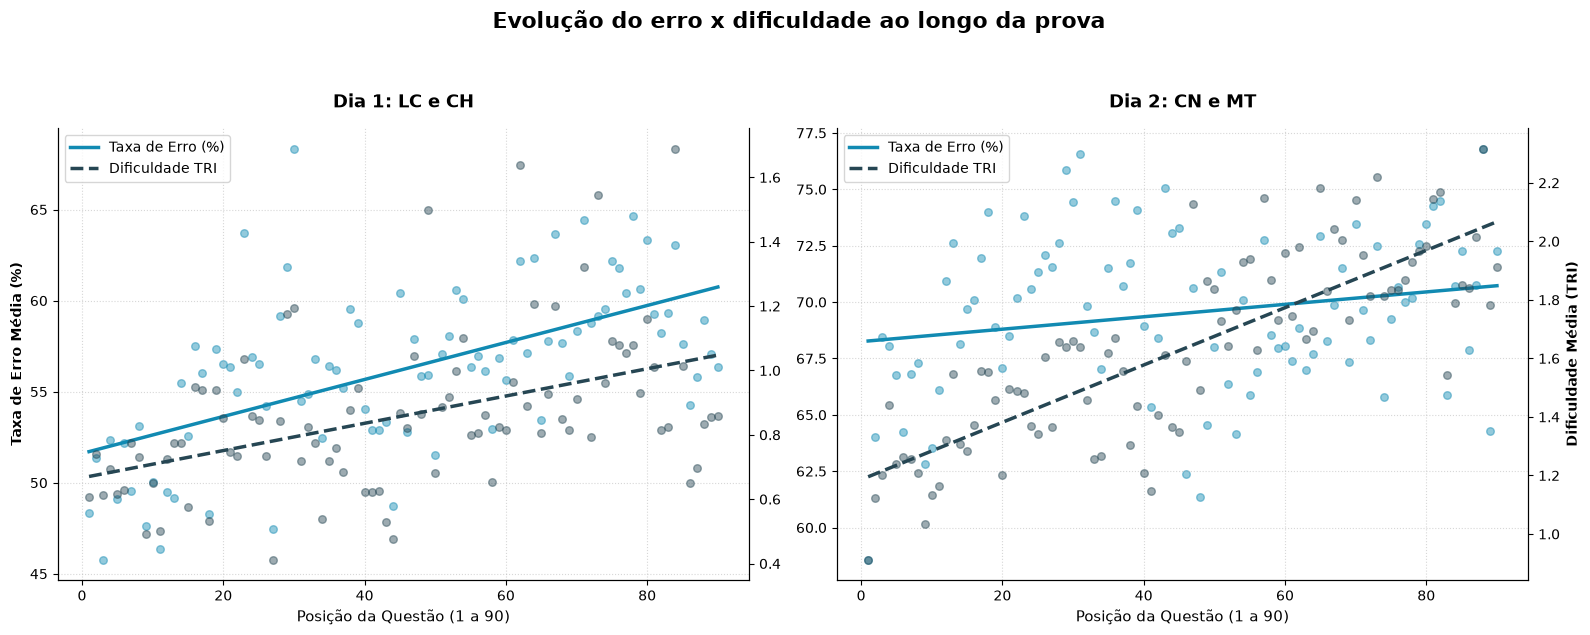

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# # Criar a moldura de uma figura com 2 posições para gráficos
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cor_dificuldade = '#264653'  
cor_erro = '#118AB2'

# passar esses valores dentro de listas para que o loop seja mais suave
dias = [1, 2]
titulos = ['Dia 1: LC e CH', 'Dia 2: CN e MT']

for i, dia in enumerate(dias):
    ax1 = axes[i] # define qual eixo está sendo trabalho nesse loop
    
    # filtra os dados pelo dia correspondente
    df_dia = df[df['DIA_PROVA'] == f'Dia {dia}']
    
    # Eixo y esquerdo (taxa de erro)
    sns.regplot(
        data=df_dia, 
        x='POSICAO_DIA', 
        y='TAXA_ERRO', 
        ax=ax1,
        ci=None,  # remove a sombra da margem de confiança
        color=cor_erro,
        scatter_kws={'alpha': 0.45, 's': 30}, # paraêmtros para a geração das bolhas
        line_kws={'linewidth': 2.5, 'label': 'Taxa de Erro (%)'} # parâmetros para a geração da linha
    )
    
    ax1.set_title(titulos[i], fontsize=13, fontweight='bold', pad=15) # titulo de cada gráfico
    ax1.set_xlabel('Posição da Questão (1 a 90)', fontsize=11)
    ax1.set_ylabel('Taxa de Erro Média (%)' if i == 0 else '', fontweight='bold')
    ax1.tick_params(axis='y')
    
    # Eixo y direito (dificuldade)
    ax2 = ax1.twinx() # para montar esse gráfico em cima do gráfico acima
    sns.regplot(
        data=df_dia, 
        x='POSICAO_DIA', 
        y='MEDIA_DIFICULDADE', 
        ax=ax2,
        ci=None,  # remove a sombra da margem de confiança
        color=cor_dificuldade,
        scatter_kws={'alpha': 0.45, 's': 30}, # paraêmtros para a geração das bolhas
        line_kws={'linewidth': 2.5, 'linestyle': '--', 'label': 'Dificuldade TRI'}# parâmetros para a geração da linha
    )
    
    ax2.set_ylabel('Dificuldade Média (TRI)' if i == 1 else '', fontweight='bold')
    ax2.tick_params(axis='y')
    
    # Unificação das legendas
    lines_1, labels_1 = ax1.get_legend_handles_labels() # pega os elementos da legenda do eixo esquerdo
    lines_2, labels_2 = ax2.get_legend_handles_labels( )# pega os elementos da legenda do eixo direito
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', frameon=True) # junta os dois numa legenda só
    
    # Limpeza visual
    ax1.grid(True, linestyle=':', alpha=0.5)
    ax2.grid(False) # Remove grid sobreposto
    ax1.spines['top'].set_visible(False)
    ax2.spines['top'].set_visible(False)

plt.suptitle(' Evolução do erro x dificuldade ao longo da prova', fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()

# Exportando o gráfico final em alta resolução
plt.savefig('../graficos/fadiga.png', dpi=300)

plt.show()

## Conclusões

Os gráficos dos dois dias apresentam situações diferentes e por isso analisamos individualmente cada caso.

No primeiro dia notamos que o crescimento da taxa de erro é maior que o crescimento da dificuldade. Essa visão é facilitada pela inclinação das retas no gráfico. O aumento da taxa de erro pode ser relacionado ao cansaço do estudante, pois as primeiras questões desse dia são da prova de LC e costumam trazer longos textos. A fadiga aqui vem de uma combinação de leitura, interpretação e raciocínio técnico. A redação também é um fator importante, pois o acréscimo de tempo em relação ao segundo dia é de apenas 30 minutos, tempo esse abaixo do recomendado para ser destinado a redação. Dessa forma o aluno pode consumir mais tempo que o previsto na construção do seu texto e ficar sem tempo suficiente para responder as últimas questões da prova de forma satisfatória.

Já o segundo dia traz um cenário um pouco diferente. Tanto a dificuldade da prova quanto a taxa de erro variam em patamares mais altos do que no primeiro dia (devemos ter atenção aqui ao intervalo de escala dos dois gráficos). A dificuldade varia positivamente de forma bem mais intensa, evidenciado pela inclinação da reta de tendência, enquanto a taxa de erro tem uma variação bem mais leve. O principal fator de esgotamento dos estudantes aqui não é mais necessariamente longos textos, mas sim o nível de dificuldade mais elevado das questões já desde o começo da prova. A linha de tendência do erro gira em torno de um platô de 70%, o que pode ser explicado pelo aumento de "chutes" de alunos exaustos. A notória diferença entre a inclinação das retas evidencia que o aumento significativo de dificuldade não causa impacto proporcional na taxa de erro.